# Chain vs. Independent Restaurants

**Question:** Do chain restaurants fail Chicago food inspections less often than independent restaurants?

There is no chain column in the data so we create one with seeing if a restaurant has 5 or more different locations.

## Data prep:

In [39]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

inspections = pd.read_csv("data/raw/Food_Inspections_20261012.csv", low_memory=False)

inspection_columns = [
    "Inspection ID", "DBA Name", "License #", "Facility Type", "Address", "Zip",
    "Inspection Date", "Inspection Type", "Risk", "Results"
]
data = inspections[inspection_columns].copy()

data["Inspection Date"] = pd.to_datetime(data["Inspection Date"], errors="coerce")
data["License #"] = pd.to_numeric(data["License #"], errors="coerce")

data = data[
    (data["Facility Type"] == "Restaurant")
    & data["Results"].isin(["Pass", "Pass w/ Conditions", "Fail"])
    & data["Inspection Type"].isin(["Canvass", "License"])
    & (data["License #"] > 0)
]

data = data.dropna(subset=["Inspection Date", "Zip", "Risk", "DBA Name", "Address"])
data = data[data["Risk"] != "All"]
data = data.drop_duplicates(subset="Inspection ID")
data = (
    data.sort_values("Inspection ID")
    .drop_duplicates(subset=["License #", "Inspection Date", "Inspection Type"])
)

data["year"] = data["Inspection Date"].dt.year
data["month"] = data["Inspection Date"].dt.month
data["Zip"] = data["Zip"].astype(int).astype(str)

print(f"Eligible inspections: {len(data):,}")

Eligible inspections: 111,554


## Chain label:

In [40]:
def clean_name(name):
    name = str(name).upper().replace("&", " AND ")
    name = re.sub(r"#\s*\d+", " ", name)
    name = re.sub(r"[^A-Z0-9 ]", "", name)
    name = re.sub(r"\b(LLC|INC|CORP|CO|LTD|THE|RESTAURANT)\b", " ", name)
    return re.sub(r"\s+", " ", name).strip()

data["brand"] = data["DBA Name"].map(clean_name)

brand_fixes = {
    "MCDONALDS": r"^(?:MC DONALDS|HALE MCDONALDS)",
    "KFC": r"^KENTUCKY FRIED",
}
for brand, pattern in brand_fixes.items():
    data.loc[data["brand"].str.contains(pattern), "brand"] = brand

caterers = "ARAMARK|EUREST|SODEXO|LEVY|CHARTWELLS|BON APPETIT|HMSHOST|SPORTSERVICE|UNITED CLUB"
data = data[~data["brand"].str.contains(caterers) & (data["brand"] != "TBD")].copy()

data["address_clean"] = data["Address"].str.upper().str.replace(r"[^A-Z0-9 ]", "", regex=True).str.split().str.join(" ")

name_locations = data.groupby("brand")["address_clean"].nunique()
generic = {"PIZZA", "CAFE", "GRILL", "TACO", "KITCHEN"}
common_names = sorted(
    [name for name in name_locations[name_locations >= 5].index if name not in generic],
    key=len
)

def find_brand(name):
    for common in common_names:
        if name == common or name.startswith(common + " "):
            return common
    return name

data["brand"] = data["brand"].map(find_brand)

locations = data.groupby("brand")["address_clean"].nunique()
data["locations"] = data["brand"].map(locations)
data["is_chain"] = (data["locations"] >= 5).astype(int)

print(f"Chain brands found: {data.loc[data['is_chain'] == 1, 'brand'].nunique()}")
display(
    data[data["is_chain"] == 1]
    .groupby("brand")["locations"].first()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Chicago locations")
)

Chain brands found: 167


,Chicago locations
brand,
SUBWAY,290
DUNKIN,240
STARBUCKS,198
MCDONALDS,117
HAROLDS CHICKEN,66
JIMMY JOHNS,57
BURGER KING,57
LA MICHOACANA,51
TACO BELL,48


## Look at the data for independent and chain:

,inspections,restaurants,fail_rate
is_chain,,,
Independent,89439,22274,0.259585
Chain,21000,3924,0.190524


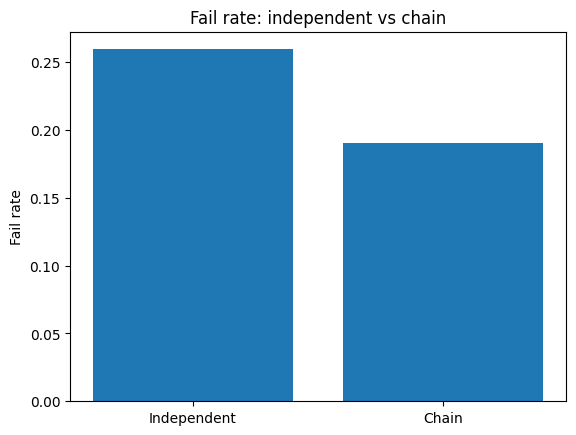

In [41]:
data["fail"] = data["Results"].eq("Fail").astype(int)

summary = (
    data.groupby("is_chain")
    .agg(inspections=("fail", "size"), restaurants=("License #", "nunique"), fail_rate=("fail", "mean"))
    .rename(index={0: "Independent", 1: "Chain"})
)
display(summary)
plt.bar(summary.index, summary["fail_rate"])
plt.title("Fail rate: independent vs chain")
plt.ylabel("Fail rate")
plt.show()

## Features:

In [42]:
cat = ['Risk', 'Inspection Type', 'Zip']
num = ['year', 'month']
chain = ['is_chain']

X = data[cat + num + chain].copy()
y = data['fail']

print('X shape:', X.shape)
display(
    y.value_counts()
    .sort_index()
    .rename(index={0: 'Pass (0)', 1: 'Fail (1)'})
    .to_frame('count')
)

X shape: (110439, 6)


,count
fail,
Pass (0),83221
Fail (1),27218


## Classification:

In [43]:
def learn_classifier():
    prep = ColumnTransformer([
        (
            'numeric',
            Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scale', StandardScaler())
            ]),
            num
        ),
        (
            'categorical',
            Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))
            ]),
            cat
        ),
        ('chain', 'passthrough', chain),
    ])

    return Pipeline([
        ('prep', prep),
        ('model', LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ))
    ])

baseline = DummyClassifier(strategy='most_frequent')
classifier = learn_classifier()

print(baseline)
print(classifier)

DummyClassifier(strategy='most_frequent')
Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['year', 'month']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                   

## Evaluation:

In [44]:
def cross_validate_classifier(model, X, y, cv, scoring):
    results = cross_validate(
        model, X, y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    return {
        metric: results[f'test_{metric}'].mean()
        for metric in scoring
    }

kf = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=1
)

scoring = {
    'accuracy': 'accuracy',
    'precision_fail': make_scorer(precision_score, zero_division=0),
    'recall_fail': make_scorer(recall_score, zero_division=0),
    'f1_fail': make_scorer(f1_score, zero_division=0)
}

baseline_scores = cross_validate_classifier(baseline, X, y, kf, scoring)
classifier_scores = cross_validate_classifier(classifier, X, y, kf, scoring)

scores = pd.DataFrame(
    [baseline_scores, classifier_scores],
    index=['Majority baseline', 'Logistic regression']
)

display(scores.style.format('{:.3f}'))

,accuracy,precision_fail,recall_fail,f1_fail
Majority baseline,0.754,0.000,0.000,0.000
Logistic regression,0.551,0.300,0.617,0.404


## Analysis:

From the data we see that chains failed 19.1% of routine inspections while independent restaurants failed 26% which is a gap of about 7%.

Our balanced logistic regression model was able to get 55.1% accuracy with a failure precision of 30%, a failure recall of 61.7%, and an F1-score of 40.4%. Our model has a lower accuracy than the baseline (75.4%), but the baseline never predicts a fail, so it misses every failed inspection. There are quite a few false predictions made by our model, since only 30% of the inspections it predicted to fail actually failed. With a 61.7% failure recall, our model is still able to catch most of the inspections that actually failed.

From these results we can tell that there is a link between chain restaurants and failing inspections less often than independent restaurants. However, being a chain is not enough by itself to predict whether a single inspection will fail. Our model could improve with more data about each restaurant and we could look into different models to see which would work better here.